# 統計的機械翻訳の基礎（IBM Model 1）と BLEU 評価

書籍 第4章「言語生成問題の解き方」（4-2-2 統計ベース、4-2-4 評価・図 4.11）に対応する演習ノートブックです。
CPU のみ・数秒で実行でき、統計的機械翻訳の核となる概念と、生成タスクの代表的な自動評価尺度 **BLEU** を体験します。

1. **IBM Model 1（EM アルゴリズム）による単語アライメントと対訳確率の学習**（4-2-2、p.139〜142）
2. **翻訳モデル × 言語モデル（ノイジーチャネルモデル）による語順選択**（4-2-2、p.141）
3. **BLEU の定義式実装（クリッピング・簡潔性ペナルティ）と `sacrebleu` との一致確認**（4-2-4、p.153）
4. **図 4.11（p.154）の再現**：シングルリファレンス vs マルチリファレンス BLEU-2、および文単位 BLEU（脚注 43）
5. **表層一致に基づく評価尺度の限界**（言い換え・語順・否定反転）

In [1]:
!pip install -q sacrebleu

In [2]:
import math
from collections import Counter, defaultdict

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sacrebleu

---

## 1. IBM Model 1（EM アルゴリズム）による単語アライメント獲得（4-2-2）

統計的機械翻訳では、対訳コーパスから**どの原言語単語がどの目的言語単語に対応するか（単語アライメント）**を教師なしで推定する **IBM Model 1** が基礎となります。
わずかな英日対訳文ペアに対して EM アルゴリズムを数回反復するだけで、対訳確率 $t(f \mid e)$ が自然に収束する様子を確認しましょう。

In [3]:
parallel_corpus = [
    (["i", "like", "cats"], ["私", "は", "猫", "が", "好き"]),
    (["i", "like", "dogs"], ["私", "は", "犬", "が", "好き"]),
    (["she", "likes", "music"], ["彼女", "は", "音楽", "が", "好き"]),
    (["he", "likes", "books"], ["彼", "は", "本", "が", "好き"]),
    (["i", "read", "books"], ["私", "は", "本", "を", "読む"]),
    (["i", "read", "a", "book"], ["私", "は", "本", "を", "読む"]),
    (["she", "reads", "a", "book"], ["彼女", "は", "本", "を", "読む"]),
    (["he", "writes", "a", "book"], ["彼", "は", "本", "を", "書く"]),
    (["big", "book"], ["大きな", "本"]),
    (["small", "book"], ["小さな", "本"]),
    (["big", "cats", "run"], ["大きな", "猫", "が", "走る"]),
    (["big", "dogs", "run"], ["大きな", "犬", "が", "走る"]),
    (["small", "cats", "sleep"], ["小さな", "猫", "が", "眠る"]),
    (["small", "dogs", "sleep"], ["小さな", "犬", "が", "眠る"]),
    (["dogs", "sleep"], ["犬", "が", "眠る"]),
    (["i", "see", "big", "cats"], ["私", "は", "大きな", "猫", "を", "見る"]),
]

def train_ibm_model1(pairs, n_iter=20):
    en_vocab = {"<NULL>"} | {w for en, _ in pairs for w in en}
    ja_vocab = {w for _, ja in pairs for w in ja}
    # 初期値は一様分布
    t = defaultdict(lambda: 1.0 / len(ja_vocab))

    for _ in range(n_iter):
        count = defaultdict(float)
        total = defaultdict(float)
        for en, ja in pairs:
            en_with_null = ["<NULL>"] + en
            for f in ja:
                z = sum(t[(f, e)] for e in en_with_null)
                for e in en_with_null:
                    c = t[(f, e)] / z
                    count[(f, e)] += c
                    total[e] += c
        for (f, e), val in count.items():
            t[(f, e)] = val / total[e]
    return t

t_prob = train_ibm_model1(parallel_corpus, n_iter=20)

# 主な英単語に対して学習された上位の日本語訳確率を表示
sample_words = ["cats", "dogs", "book", "books", "read", "writes", "big", "small", "run", "sleep"]
rows = []
for ew in sample_words:
    cands = sorted(
        ((jw, p) for (jw, e), p in t_prob.items() if e == ew),
        key=lambda x: x[1],
        reverse=True,
    )[:2]
    rows.append({
        "英単語 e": ew,
        "最有力訳語 f1": f"{cands[0][0]} ({cands[0][1]:.2f})",
        "次点訳語 f2": f"{cands[1][0]} ({cands[1][1]:.2f})" if len(cands) > 1 else "-",
    })
display(pd.DataFrame(rows))

,英単語 e,最有力訳語 f1,次点訳語 f2
0,cats,猫 (0.96),が (0.04)
1,dogs,犬 (0.86),が (0.14)
2,book,本 (1.00),を (0.00)
3,books,本 (0.81),は (0.16)
4,read,読む (0.61),を (0.38)
5,writes,書く (0.83),を (0.11)
6,big,大きな (1.00),走る (0.00)
7,small,小さな (1.00),眠る (0.00)
8,run,走る (0.83),が (0.16)
9,sleep,眠る (0.84),が (0.16)


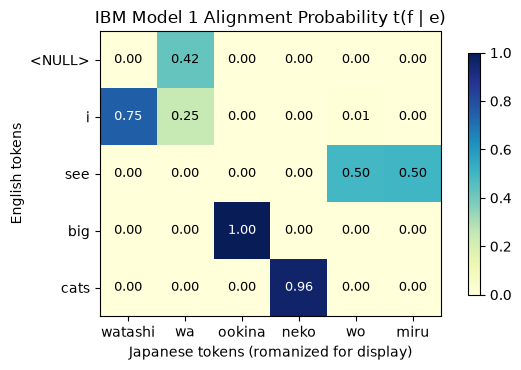

In [4]:
# 1文についてアライメント確率行列 t(f|e) をヒートマップで可視化
en_sent = ["<NULL>", "i", "see", "big", "cats"]
ja_sent = ["私", "は", "大きな", "猫", "を", "見る"]
mat = np.array([[t_prob[(f, e)] for f in ja_sent] for e in en_sent])

fig, ax = plt.subplots(figsize=(6.2, 3.8))
im = ax.imshow(mat, cmap="YlGnBu", vmin=0.0, vmax=1.0)
ax.set_xticks(range(len(ja_sent)), labels=["watashi", "wa", "ookina", "neko", "wo", "miru"])
ax.set_yticks(range(len(en_sent)), labels=en_sent)
ax.set_xlabel("Japanese tokens (romanized for display)")
ax.set_ylabel("English tokens")
ax.set_title("IBM Model 1 Alignment Probability t(f | e)")
for i in range(len(en_sent)):
    for j in range(len(ja_sent)):
        ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center",
                color="white" if mat[i, j] > 0.55 else "black", fontsize=9)
fig.colorbar(im, ax=ax, shrink=0.85)
plt.tight_layout()
plt.show()

英語の語順（S V O：`i see big cats`）と日本語の語順（S O V：`私 は 大きな 猫 を 見る`）が交差していても、`see → 見る`、`big → 大きな`、`cats → 猫` の対応を統計的に見つけられています。

さらに書籍 4-2-2（p.141）の式：

$$\hat{e} = \arg\max_e P(e \mid f) = \arg\max_e P(f \mid e) P(e)$$

のとおり、**翻訳モデル $P(f \mid e)$（単語対応の良さ）** だけでは語順がバラバラになりがちですが、**言語モデル $P(e)$（流暢さ）** を掛け合わせることで自然な語順の候補を選べます。

---

## 2. BLEU の定義式実装と検証（4-2-4、p.153）

機械翻訳の自動評価で広く使われる **BLEU** は、次の 2 要素の積で定義されます（書籍 p.153、$N$ は通常 4）。

$$\mathrm{BLEU} = \mathrm{BP} \times \exp\left(\sum_{n=1}^{N} w_n \log(p_n)\right), \quad \mathrm{BP} = \begin{cases} 1 & (c > r) \\ \exp(1 - r/c) & (c \le r) \end{cases}$$

（※ 書籍第 1 刷 p.153 では指数関数の中身が誤って逆数 `1 / ...` として記載されています（[正誤表](https://github.com/mamorlis/nlpbook/blob/main/errata.md)）。本ノートブックでは正しい定義式を実装し、`sacrebleu` と一致することを確認します。）

In [5]:
def ngrams(tokens, n):
    return [tuple(tokens[i:i + n]) for i in range(len(tokens) - n + 1)]

def compute_bleu(hypotheses, references_list, max_n=4):
    """コーパスレベル BLEU（複数リファレンス対応、smooth_method='none' 相当）"""
    clipped_counts = [0] * max_n
    total_counts = [0] * max_n
    hyp_len = 0
    ref_len = 0

    for idx, hyp in enumerate(hypotheses):
        h_tok = hyp.split()
        hyp_len += len(h_tok)
        refs_tok = [refs[idx].split() for refs in references_list]
        # 出力長に最も近い参照訳長を代表値 r とする
        ref_len += min((len(rt) for rt in refs_tok), key=lambda l: (abs(l - len(h_tok)), l))

        for n in range(1, max_n + 1):
            h_ng = Counter(ngrams(h_tok, n))
            max_r_ng = Counter()
            for rt in refs_tok:
                r_ng = Counter(ngrams(rt, n))
                for ng, cnt in r_ng.items():
                    if cnt > max_r_ng[ng]:
                        max_r_ng[ng] = cnt
            clipped_counts[n - 1] += sum(min(cnt, max_r_ng[ng]) for ng, cnt in h_ng.items())
            total_counts[n - 1] += sum(h_ng.values())

    precisions = [c / t if t > 0 else 0.0 for c, t in zip(clipped_counts, total_counts)]
    bp = 1.0 if hyp_len > ref_len else math.exp(1.0 - ref_len / hyp_len)
    if min(precisions) == 0.0:
        bleu = 0.0
    else:
        bleu = bp * math.exp(sum(math.log(p) for p in precisions) / max_n)
    return bleu * 100.0, [p * 100.0 for p in precisions], bp

refs = [
    "the cat is on the mat",
    "there is a cat on the mat",
]
hyps = [
    "the cat is on the mat",
    "there is a dog on the mat",
]

my_bleu, precs, bp = compute_bleu(hyps, [refs], max_n=4)
lib_bleu = sacrebleu.corpus_bleu(hyps, [refs], tokenize="none", smooth_method="none")
print(f"手計算 BLEU   = {my_bleu:.4f} (n-gram 適合率={[round(p, 2) for p in precs]}, BP={bp:.4f})")
print(f"sacrebleu     = {lib_bleu.score:.4f}")

手計算 BLEU   = 68.1561 (n-gram 適合率=[92.31, 81.82, 66.67, 42.86], BP=1.0000)
sacrebleu     = 68.1561


### クリッピングと簡潔性ペナルティの働きを確認する

In [6]:
ref_sample = ["the cat is on the mat"]
cases = [
    ("適切な翻訳（完全一致）", ["the cat is on the mat"]),
    ("同じ語を連呼（クリッピングの検証）", ["the the the the the the"]),
    ("極端に短い出力（BP の検証）", ["the cat"]),
]

for label, h in cases:
    b_none = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="none")
    b_exp = sacrebleu.corpus_bleu(h, [ref_sample], tokenize="none", smooth_method="exp")
    print(f"{label:32s} | BLEU(none)={b_none.score:6.2f}, BLEU(smooth)={b_exp.score:6.2f}, BP={b_none.bp:.3f}, p1={b_none.precisions[0]:.1f}")

適切な翻訳（完全一致）                      | BLEU(none)=100.00, BLEU(smooth)=100.00, BP=1.000, p1=100.0
同じ語を連呼（クリッピングの検証）                | BLEU(none)=  0.00, BLEU(smooth)=  9.65, BP=1.000, p1=33.3
極端に短い出力（BP の検証）                  | BLEU(none)=  0.00, BLEU(smooth)=  0.00, BP=0.135, p1=100.0


- `"the the the the the the"` は 6 単語すべてが参照文の `"the"` と一致するため、クリッピングなしでは 1-gram 適合率が 100% になってしまいますが、クリッピングにより参照文中の出現回数（2回）までに制限され、`p1 = 33.3`、2-gram 以降は 0 のため BLEU は低くなります。
- `"the cat"` は 1-gram・2-gram 適合率が 100% ですが、文長が短すぎるため `BP = 0.135` と強いペナルティが掛かります。

---

## 3. 図 4.11（p.154）の再現：シングルリファレンス vs マルチリファレンスと文単位 BLEU

書籍 p.153〜154 では、同じ出力に対して **参照訳（リファレンス）を増やすと BLEU スコアが大きく上がる** 例（図 4.11：`BLEU-2 = 0.38` → `0.71`）と、元々の BLEU は**コーパス単位で測ることを前提としており、文単位（`sentenceBLEU`）では不安定になりやすい**注意点（脚注 43）が解説されています。

In [7]:
# 書籍 p.154 の記述に合わせた 8 単語出力と 2 つの参照訳
# 共通バイグラム: "it is", "like a", "language to", "to me"
hyp_411 = ["it is like a new language to me"]
ref1_411 = ["yes it is one difficult language to study"]
ref2_411 = ["actually that seems like a good topic to me"]

bleu2_single, p_single, bp_single = compute_bleu(hyp_411, [ref1_411], max_n=2)
bleu2_multi, p_multi, bp_multi = compute_bleu(hyp_411, [ref1_411, ref2_411], max_n=2)

print("=== 書籍 図 4.11（BLEU-2）の比較 ===")
print(f"シングルリファレンス : p1={p_single[0]/100:.2f}, p2={p_single[1]/100:.2f}, BP={bp_single:.2f}, BLEU-2={bleu2_single/100:.2f}")
print(f"マルチリファレンス   : p1={p_multi[0]/100:.2f}, p2={p_multi[1]/100:.2f}, BP={bp_multi:.2f}, BLEU-2={bleu2_multi/100:.2f}")

# 文単位 (sentence_bleu) とコーパス単位でのスムージング有無の違い
s1 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0]]).score
s2 = sacrebleu.sentence_bleu(hyp_411[0], [ref1_411[0], ref2_411[0]]).score
print(f"\n[参考: 4-gram sentenceBLEU (sacrebleu)] single={s1:.2f}, multi={s2:.2f}")

=== 書籍 図 4.11（BLEU-2）の比較 ===
シングルリファレンス : p1=0.50, p2=0.29, BP=1.00, BLEU-2=0.38
マルチリファレンス   : p1=0.88, p2=0.57, BP=1.00, BLEU-2=0.71

[参考: 4-gram sentenceBLEU (sacrebleu)] single=15.62, multi=21.36


同じ出力文・同じモデルでも、参照訳の数や評価設定を変えるだけでスコアは大きく変わります（書籍 p.153 脚注 42：「違う設定での BLEU スコアの絶対値の比較には意味がない」）。

---

## 4. 表層一致に基づく評価尺度の限界

BLEU は高速で再現性が高い一方、**表層的な n-gram の一致**しか見ないため、言い換えや否定語の有無に対して直感とズレることがあります。

In [8]:
ref_en = ["I bought a new book at the bookstore yesterday"]
examples = [
    ("参照文と同一", "I bought a new book at the bookstore yesterday"),
    ("意味は同じ（言い換え）", "Yesterday I purchased a brand new book from the shop"),
    ("語順を崩した非流暢な文", "yesterday book new a bought I bookstore the at"),
    ("否定が逆（意味は真逆）", "I did not buy a new book at the bookstore yesterday"),
]

eval_rows = []
for desc, hyp in examples:
    res = sacrebleu.corpus_bleu([hyp], [ref_en], tokenize="none")
    eval_rows.append({
        "ケース": desc,
        "出力文": hyp,
        "BLEU": round(res.score, 2),
        "1-gram": round(res.precisions[0], 1),
        "4-gram": round(res.precisions[3], 1),
    })

pd.DataFrame(eval_rows)

,ケース,出力文,BLEU,1-gram,4-gram
0,参照文と同一,I bought a new book at the bookstore yesterday,100.00,100.0,100.0
1,意味は同じ（言い換え）,Yesterday I purchased a brand new book from th...,10.55,50.0,3.6
2,語順を崩した非流暢な文,yesterday book new a bought I bookstore the at,8.26,100.0,2.1
3,否定が逆（意味は真逆）,I did not buy a new book at the bookstore yest...,59.00,72.7,50.0


- **言い換えに厳しい**: 意味がほぼ同じでも異なる単語（`bought` → `purchased`、`bookstore` → `shop`）を使うと BLEU が大きく下がります。
- **否定や重要語の反転に鈍感**: `"not"` を 1 語足して意味が真逆になっても、多くの n-gram が一致するため高い BLEU がついてしまいます。

この限界を補うアプローチとして、第 2 章の[品質推定の演習](https://colab.research.google.com/github/mamorlis/nlpbook/blob/main/notebooks/ch2_qe.ipynb)（COMET-QE 等）があります。